###  <font color="#020f0f"> Dataset Creation </font>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)

n = 60

distance = np.random.randint(10, 501, n)
shipment_volume = np.random.randint(20, 201, n)
transport_cost = (
    150 + distance * 4.2 + shipment_volume * 2.5
    + np.random.normal(0, 180, n)
)
delivery_time = (
    2 + distance / 80
    + np.random.normal(0, 1.2, n)
)
delivery_time = np.maximum(delivery_time, 0.5)

delivery_status = np.where(
    delivery_time > 6,
    "Delayed",
    "On Time"
)

regions = np.random.choice(
    ["North", "South", "East", "West"],
    size=n
)

df = pd.DataFrame({
    "Shipment_ID": range(1001, 1001 + n),
    "Region": regions,
    "Distance_KM": distance,
    "Shipment_Volume": shipment_volume,
    "Transport_Cost": transport_cost.round(2),
    "Delivery_Time_Hours": delivery_time.round(2),
    "Delivery_Status": delivery_status
})

df.to_csv("week3_logistics_data.csv", index=False)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head(10))


Dataset created successfully!
Dataset shape: (60, 7)


,Shipment_ID,Region,Distance_KM,Shipment_Volume,Transport_Cost,Delivery_Time_Hours,Delivery_Status
0,1001,North,112,186,1211.12,2.49,On Time
1,1002,North,445,37,2142.75,8.11,Delayed
2,1003,West,358,151,2150.31,6.40,Delayed
3,1004,North,280,108,1639.40,5.91,On Time
4,1005,West,116,79,804.42,3.35,On Time
5,1006,North,81,33,782.36,2.72,On Time
6,1007,South,198,28,1007.37,6.20,Delayed
7,1008,North,30,109,409.96,3.65,On Time
8,1009,West,112,72,1018.59,0.50,On Time
9,1010,West,131,149,1294.73,5.41,On Time


###  <font color="#020f0f"> Initial EDA </font>

In [3]:
print("Dataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nDelivery status counts:")
print(df["Delivery_Status"].value_counts())

print("\nAverage metrics by region:")
display(
    df.groupby("Region")[
        ["Distance_KM", "Shipment_Volume",
         "Transport_Cost", "Delivery_Time_Hours"]
    ].mean().round(2)
)

print("\nCorrelation matrix:")
display(
    df[[
        "Distance_KM",
        "Shipment_Volume",
        "Transport_Cost",
        "Delivery_Time_Hours"
    ]].corr().round(2)
)


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Shipment_ID          60 non-null     int64  
 1   Region               60 non-null     str    
 2   Distance_KM          60 non-null     int32  
 3   Shipment_Volume      60 non-null     int32  
 4   Transport_Cost       60 non-null     float64
 5   Delivery_Time_Hours  60 non-null     float64
 6   Delivery_Status      60 non-null     str    
dtypes: float64(2), int32(2), int64(1), str(2)
memory usage: 3.6 KB

Summary statistics:


,Shipment_ID,Distance_KM,Shipment_Volume,Transport_Cost,Delivery_Time_Hours
count,60.000000,60.000000,60.000000,60.000000,60.00000
mean,1030.500000,261.650000,103.316667,1488.361667,5.40000
std,17.464249,142.650316,52.551344,652.451189,2.25074
min,1001.000000,30.000000,21.000000,409.960000,0.50000
25%,1015.750000,140.000000,62.250000,997.502500,3.49000
50%,1030.500000,264.500000,102.000000,1496.450000,5.67500
75%,1045.250000,370.000000,151.000000,2056.987500,6.92250
max,1060.000000,494.000000,194.000000,2785.610000,10.54000



Delivery status counts:
Delivery_Status
On Time    34
Delayed    26
Name: count, dtype: int64

Average metrics by region:


,Distance_KM,Shipment_Volume,Transport_Cost,Delivery_Time_Hours
Region,,,,
East,207.36,112.36,1324.41,4.55
North,268.65,103.94,1529.59,5.52
South,279.83,88.92,1525.62,5.41
West,274.65,106.45,1521.14,5.76



Correlation matrix:


,Distance_KM,Shipment_Volume,Transport_Cost,Delivery_Time_Hours
Distance_KM,1.00,0.04,0.94,0.85
Shipment_Volume,0.04,1.00,0.25,-0.03
Transport_Cost,0.94,0.25,1.00,0.78
Delivery_Time_Hours,0.85,-0.03,0.78,1.00


###  <font color="#020f0f"> Visulization Folder Create </font>

In [6]:
import os

os.makedirs("visualizations", exist_ok=True)

print(" Create Visualization Folder Sucssecfully")


 Create Visualization Folder Sucssecfully


###  <font color="#020f0f"> Delivery time distribution (Histogram) </font>

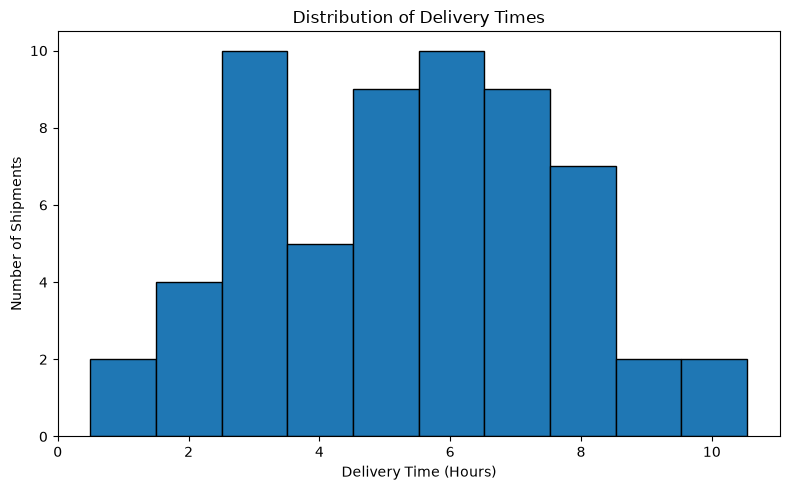

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Delivery_Time_Hours"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Delivery Times")
plt.xlabel("Delivery Time (Hours)")
plt.ylabel("Number of Shipments")
plt.tight_layout()

plt.savefig("visualizations/01_delivery_time_histogram.png", dpi=150)
plt.show()


###  <font color="#020f0f"> Region-wise average transport cost (Bar chart) </font>

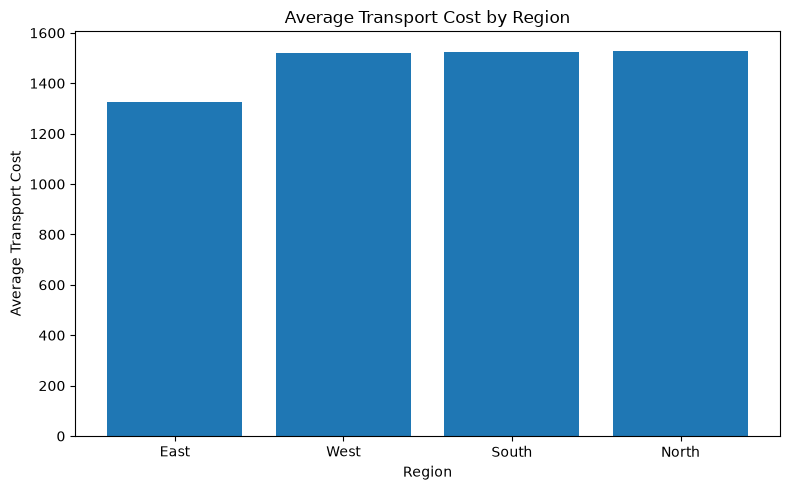

In [9]:
region_cost = df.groupby("Region")["Transport_Cost"].mean().sort_values()

plt.figure(figsize=(8, 5))

plt.bar(region_cost.index, region_cost.values)

plt.title("Average Transport Cost by Region")
plt.xlabel("Region")
plt.ylabel("Average Transport Cost")
plt.tight_layout()

plt.savefig("visualizations/02_region_transport_cost.png", dpi=150)
plt.show()


###  <font color="#020f0f">Distance vs Delivery Time (Scatter plot) </font>

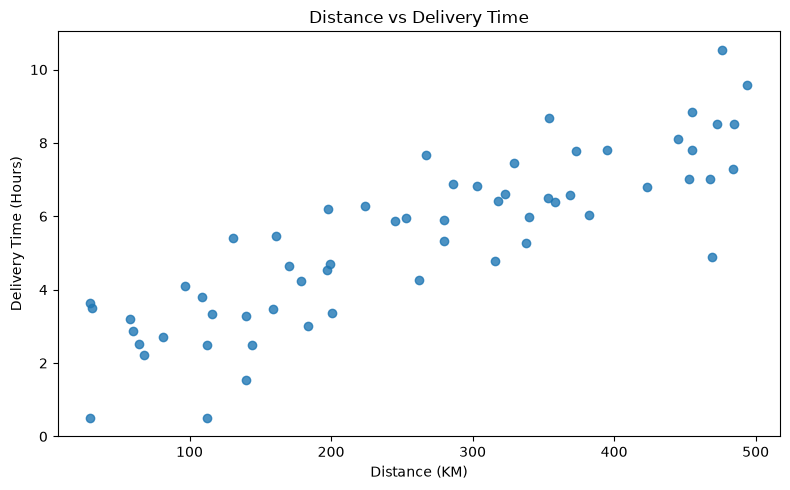

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Distance_KM"],
    df["Delivery_Time_Hours"],
    alpha=0.8
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (KM)")
plt.ylabel("Delivery Time (Hours)")
plt.tight_layout()

plt.savefig("visualizations/03_distance_vs_delivery_time.png", dpi=150)
plt.show()


###  <font color="#020f0f"> Shipment volume distribution (Box plot) </font>

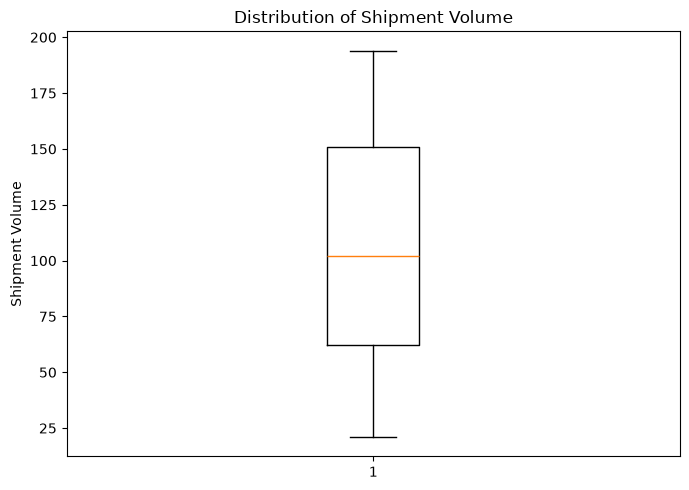

In [11]:
plt.figure(figsize=(7, 5))

plt.boxplot(df["Shipment_Volume"])

plt.title("Distribution of Shipment Volume")
plt.ylabel("Shipment Volume")
plt.tight_layout()

plt.savefig("visualizations/04_shipment_volume_boxplot.png", dpi=150)
plt.show()


###  <font color="#020f0f"> Correlation heatmap </font>

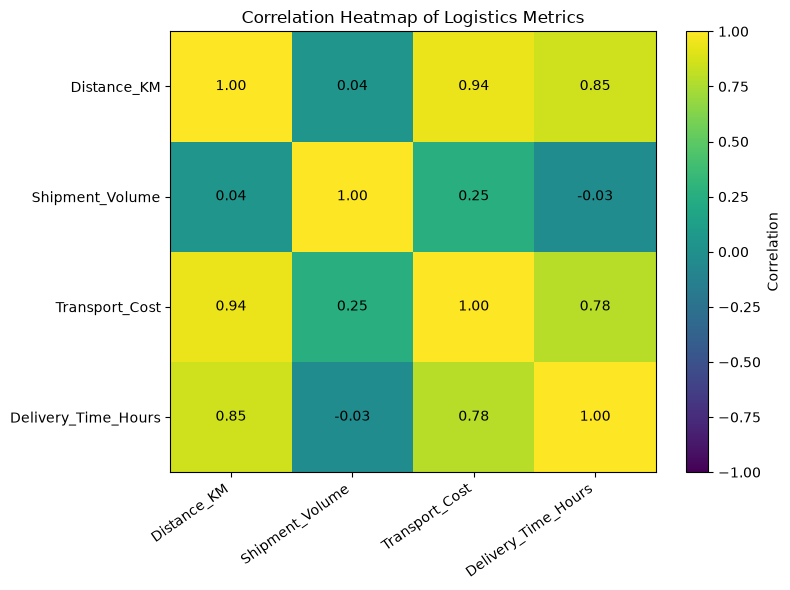

In [12]:
corr = df[[
    "Distance_KM",
    "Shipment_Volume",
    "Transport_Cost",
    "Delivery_Time_Hours"
]].corr()

plt.figure(figsize=(8, 6))

image = plt.imshow(corr, vmin=-1, vmax=1, aspect="auto")
plt.colorbar(image, label="Correlation")

plt.xticks(range(len(corr.columns)), corr.columns, rotation=35, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

plt.title("Correlation Heatmap of Logistics Metrics")
plt.tight_layout()

plt.savefig("visualizations/05_correlation_heatmap.png", dpi=150)
plt.show()


###  <font color="#020f0f"> Region-wise average delivery time </font>

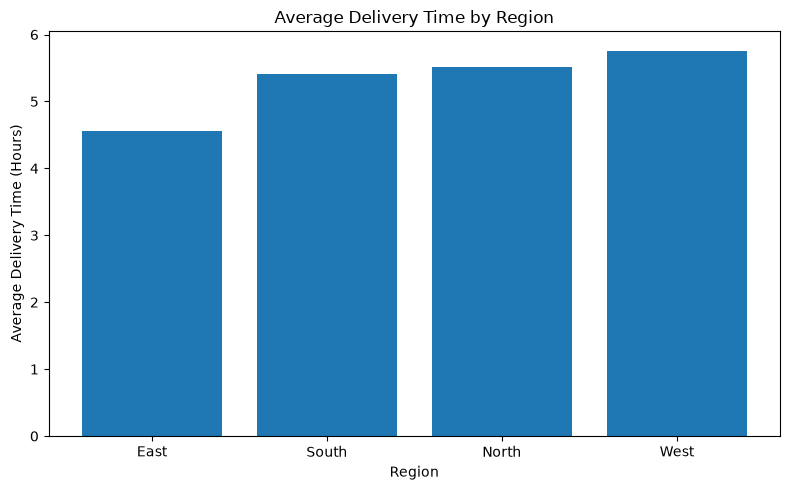

All six charts saved in the visualizations folder.


In [13]:
region_time = df.groupby("Region")["Delivery_Time_Hours"].mean().sort_values()

plt.figure(figsize=(8, 5))

plt.bar(region_time.index, region_time.values)

plt.title("Average Delivery Time by Region")
plt.xlabel("Region")
plt.ylabel("Average Delivery Time (Hours)")
plt.tight_layout()

plt.savefig("visualizations/06_region_delivery_time.png", dpi=150)
plt.show()

print("All six charts saved in the visualizations folder.")


###  <font color="#020f0f"> Analytical insights and KPI analysis </font>

In [14]:
on_time_rate = (
    (df["Delivery_Status"] == "On Time").mean() * 100
)

delayed_rate = (
    (df["Delivery_Status"] == "Delayed").mean() * 100
)

avg_delivery_time = df["Delivery_Time_Hours"].mean()
median_delivery_time = df["Delivery_Time_Hours"].median()
avg_transport_cost = df["Transport_Cost"].mean()
avg_distance = df["Distance_KM"].mean()

distance_time_corr = df["Distance_KM"].corr(
    df["Delivery_Time_Hours"]
)

distance_cost_corr = df["Distance_KM"].corr(
    df["Transport_Cost"]
)

print("LOGISTICS PERFORMANCE SUMMARY")
print("-" * 35)
print(f"Total shipments: {len(df)}")
print(f"On-time delivery rate: {on_time_rate:.2f}%")
print(f"Delayed delivery rate: {delayed_rate:.2f}%")
print(f"Average delivery time: {avg_delivery_time:.2f} hours")
print(f"Median delivery time: {median_delivery_time:.2f} hours")
print(f"Average transport cost: {avg_transport_cost:.2f}")
print(f"Average distance: {avg_distance:.2f} KM")
print(f"Distance-time correlation: {distance_time_corr:.2f}")
print(f"Distance-cost correlation: {distance_cost_corr:.2f}")

print("\nREGION-WISE PERFORMANCE")
region_summary = df.groupby("Region").agg(
    Shipments=("Shipment_ID", "count"),
    Avg_Delivery_Time=("Delivery_Time_Hours", "mean"),
    Avg_Transport_Cost=("Transport_Cost", "mean"),
    Avg_Distance=("Distance_KM", "mean")
).round(2)

display(region_summary)

region_summary.to_csv("week3_region_summary.csv")


LOGISTICS PERFORMANCE SUMMARY
-----------------------------------
Total shipments: 60
On-time delivery rate: 56.67%
Delayed delivery rate: 43.33%
Average delivery time: 5.40 hours
Median delivery time: 5.67 hours
Average transport cost: 1488.36
Average distance: 261.65 KM
Distance-time correlation: 0.85
Distance-cost correlation: 0.94

REGION-WISE PERFORMANCE


,Shipments,Avg_Delivery_Time,Avg_Transport_Cost,Avg_Distance
Region,,,,
East,11,4.55,1324.41,207.36
North,17,5.52,1529.59,268.65
South,12,5.41,1525.62,279.83
West,20,5.76,1521.14,274.65


#  <font color="#020f0f"> ANALYTICAL OBSERVATIONS </font>

In [15]:
slowest_region = region_summary["Avg_Delivery_Time"].idxmax()
highest_cost_region = region_summary["Avg_Transport_Cost"].idxmax()

print("ANALYTICAL OBSERVATIONS")
print("-" * 35)

print(
    f"1. Highest average delivery time: {slowest_region} "
    f"({region_summary.loc[slowest_region, 'Avg_Delivery_Time']:.2f} hours)"
)

print(
    f"2. Highest average transport cost: {highest_cost_region} "
    f"({region_summary.loc[highest_cost_region, 'Avg_Transport_Cost']:.2f})"
)

if distance_time_corr > 0.5:
    print("3. Distance and delivery time show a strong positive correlation.")
elif distance_time_corr > 0:
    print("3. Distance and delivery time show a positive correlation.")
elif distance_time_corr < 0:
    print("3. Distance and delivery time show a negative correlation.")
else:
    print("3. Distance and delivery time show approximately no linear correlation.")

print(
    "4. These are observations from simulated data, "
    "not conclusions about a real logistics company."
)


ANALYTICAL OBSERVATIONS
-----------------------------------
1. Highest average delivery time: West (5.76 hours)
2. Highest average transport cost: North (1529.59)
3. Distance and delivery time show a strong positive correlation.
4. These are observations from simulated data, not conclusions about a real logistics company.


###  <font color="#020f0f"> Project Output </font>